In [1]:
#Cell 0 GPU
import torch, os
print("torch.cuda.is_available() =",torch.cuda.is_available())
if torch.cuda.is_available():
  print("Yay")
else:
  print("Nay")

torch.cuda.is_available() = True
Yay


In [2]:
# Safe mount + ensure checkpoint dir creation (run as one cell)
import os, subprocess, time
from google.colab import drive

def try_mount(mp):
    try:
        drive.mount(mp, force_remount=True)
        return True, None
    except Exception as e:
        return False, e

print("1) Attempting to flush/unmount any stale mount...")
try:
    drive.flush_and_unmount()
    print("  flush_and_unmount() succeeded (or no stale mount).")
except Exception as e:
    print("  flush_and_unmount() raised:", repr(e))

print("\n2) Attempting fusermount -u /content/drive (may not be present)...")
try:
    res = subprocess.run(['fusermount','-u','/content/drive'], capture_output=True, text=True)
    print("  fusermount exit:", res.returncode)
    if res.stdout.strip(): print("  stdout:", res.stdout.strip())
    if res.stderr.strip(): print("  stderr:", res.stderr.strip())
except Exception as e:
    print("  fusermount not available or failed:", repr(e))

print("\n3) Trying to mount to common mountpoints in order: /content/drive then /content/gdrive")
mount_point = None
for mp in ['/content/drive', '/content/gdrive']:
    print("  -> trying", mp)
    ok, err = try_mount(mp)
    if ok:
        mount_point = mp
        print("     mounted to", mp)
        break
    else:
        print("     mount failed:", repr(err))

# Choose where to create checkpoint dir
if mount_point:
    # Prefer the MyDrive path if available
    mydrive_path = os.path.join(mount_point, 'MyDrive')
    if os.path.isdir(mydrive_path):
        base = mydrive_path
    else:
        # If MyDrive is not present, fallback to the root of the mountpoint (print listing to debug)
        print("  NOTE: 'MyDrive' not found under", mount_point, "- listing contents:")
        try:
            print("   ", os.listdir(mount_point)[:50])
        except Exception as e:
            print("   could not list:", e)
        base = mount_point

    CPKT_DIR = os.path.join(base, 'gpt2_agnews_checkpoints1')
    try:
        os.makedirs(CPKT_DIR, exist_ok=True)
        print("\n✅ Checkpoint directory created/verified at:", CPKT_DIR)
    except Exception as e:
        print("\n❌ Failed to create checkpoint dir at", CPKT_DIR, " —", repr(e))
        # fallback to local /content
        fallback = '/content/gpt2_agnews_checkpoints1'
        os.makedirs(fallback, exist_ok=True)
        CPKT_DIR = fallback
        print("Using fallback local directory:", CPKT_DIR)
else:
    # Could not mount Google Drive — create a local directory so your training won't crash
    fallback = '/content/gpt2_agnews_checkpoints1'
    os.makedirs(fallback, exist_ok=True)
    CPKT_DIR = fallback
    print("\n⚠️ Could not mount Google Drive. Created local fallback:", CPKT_DIR)
    print("   If you want these saved to Drive, re-run the cell after fixing the mount or mount manually.")

# Expose and print final chosen CPKT_DIR
print("\nFINAL: CPKT_DIR =", CPKT_DIR, " | exists:", os.path.exists(CPKT_DIR))


1) Attempting to flush/unmount any stale mount...
  flush_and_unmount() succeeded (or no stale mount).

2) Attempting fusermount -u /content/drive (may not be present)...
  fusermount exit: 1
  stderr: fusermount: failed to unmount /content/drive: No such file or directory

3) Trying to mount to common mountpoints in order: /content/drive then /content/gdrive
  -> trying /content/drive
Mounted at /content/drive
     mounted to /content/drive

✅ Checkpoint directory created/verified at: /content/drive/MyDrive/gpt2_agnews_checkpoints1

FINAL: CPKT_DIR = /content/drive/MyDrive/gpt2_agnews_checkpoints1  | exists: True


In [3]:
#Cell 2 - Install packages
!pip install -q transformers datasets accelerate bitsandbytes scikit-learn psutil matplotlib

In [4]:
# 1) upgrade
!pip install -q -U "transformers" "datasets" "accelerate"



In [5]:
#Cell 3 imports and utils
import os, time
import torch
import numpy as np
from datasets import load_dataset
from transformers import AutoTokenizer, AutoConfig, AutoModelForCausalLM, TrainingArguments, Trainer, DataCollatorWithPadding
from torch import nn
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import psutil

def cpu_memory_mb():
  proc = psutil.Process(os.getpid())
  return proc.memory_info().rss / (1024**2)


def print_mem():
  print(f"CPU RAM (MB): {cpu_memory_mb():.1f}")
  if torch.cuda.is_available():
    print(f"CUDA allocated (MB): {torch.cuda.memory_allocated()/1024**2:.1f}")


print('Imports OK')

Imports OK


In [6]:
MODEL_NAME = 'gpt2' # GPT-2 Small (124M)
MAX_LENGTH = 128


raw = load_dataset('ag_news')
from transformers import AutoTokenizer


tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
# GPT-2 tokenizer has no pad token by default — set pad to eos
if tokenizer.pad_token is None:
  tokenizer.pad_token = tokenizer.eos_token


print('Dataset sizes:', {k: len(raw[k]) for k in raw})


# Preprocessing
def preprocess_batch(examples):
  texts = examples['text']
  enc = tokenizer(texts, padding='max_length', truncation=True, max_length=MAX_LENGTH)
  enc['labels'] = examples['label']
  return enc


train = raw['train'].map(preprocess_batch, batched=True, remove_columns=raw['train'].column_names)
test = raw['test'].map(preprocess_batch, batched=True, remove_columns=raw['test'].column_names)


from transformers import DataCollatorWithPadding
collator = DataCollatorWithPadding(tokenizer)


print('Tokenization complete')
print_mem()

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Dataset sizes: {'train': 120000, 'test': 7600}
Tokenization complete
CPU RAM (MB): 1456.6
CUDA allocated (MB): 0.0


In [7]:
#Cell 5
class GPT2forClassification(nn.Module):
  def __init__(self, model_name='gpt2',num_labels=4):
    super().__init__()
    self.gpt = AutoModelForCausalLM.from_pretrained(model_name)
    hidden_size = self.gpt.config.hidden_size #Just loading
    self.classifier = nn.Linear(hidden_size, num_labels)

  def forward(self,input_ids=None, attention_mask=None,labels=None):
    outputs = self.gpt.model(input_ids=input_ids, attention_mask=attention_mask, return_dict=True)
    last_hidden = outputs.last_hidden_state # (B, L, H)
    seq_lens = attention_mask.sum(dim=1) - 1
    batch_idxs = torch.arange(last_hidden.size(0), device=last_hidden.device)
    pooled = last_hidden[batch_idxs, seq_lens] # (B, H)
    logits = self.classifier(pooled)
    loss = None
    if labels is not None:
      loss_fct = nn.CrossEntropyLoss()
      loss = loss_fct(logits.view(-1, logits.size(-1)), labels.view(-1))
      return {'loss': loss, 'logits': logits}
    return {'logits': logits}
model = GPT2forClassification(MODEL_NAME, num_labels=4)
print('Model size (params):', sum(p.numel() for p in model.parameters()))
print_mem()


Model size (params): 124442884
CPU RAM (MB): 1512.3
CUDA allocated (MB): 0.0


In [8]:
# ===== Replacement Cell: prune dataset columns & create Trainer (compatibility-safe) =====
from transformers import TrainingArguments
from transformers import Trainer as WrapperTrainer
import torch

# 1) Ensure output_dir variable exists (fix possible typo)
try:
    output_dir = CKPT_DIR
except NameError:
    output_dir = "/content/drive/MyDrive/gpt2_agnews_checkpoints"
    print("Warning: CKPT_DIR not defined — using fallback:", output_dir)

# 2) Manually prune dataset columns so Trainer won't try to remove them for us
required_cols = ["input_ids", "attention_mask", "labels"]

def prune_dataset(ds):
    # ds: a huggingface Dataset
    cols = list(ds.column_names)
    to_remove = [c for c in cols if c not in required_cols]
    if to_remove:
        print("Removing columns:", to_remove)
        # prefer remove_columns if available
        if hasattr(ds, "remove_columns"):
            return ds.remove_columns(to_remove)
        else:
            # fallback: recreate dataset with only required cols (less efficient)
            return ds.map(lambda ex: {k: ex[k] for k in required_cols}, batched=True, remove_columns=cols)
    else:
        print("No extra columns to remove.")
        return ds

train = prune_dataset(train)
test  = prune_dataset(test)

print("Train columns now:", train.column_names)
print("Test columns now: ", test.column_names)

# 3) Minimal, backward-compatible TrainingArguments (no new keywords)
training_args = TrainingArguments(
    output_dir=output_dir,
    num_train_epochs=1,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=8,
    fp16=torch.cuda.is_available(),   # keep if supported; harmless boolean otherwise
    save_steps=200,
    save_total_limit=10,
    logging_steps=50,
    report_to="none",
)

# 4) Create the Trainer without remove_unused_columns kw (older HF versions dislike it)
trainer = WrapperTrainer(
    model=model,
    args=training_args,
    train_dataset=train,
    eval_dataset=test,
    data_collator=collator,
)

print("Trainer created successfully. Training args:", training_args)


No extra columns to remove.
No extra columns to remove.
Train columns now: ['input_ids', 'attention_mask', 'labels']
Test columns now:  ['input_ids', 'attention_mask', 'labels']
Trainer created successfully. Training args: TrainingArguments(
_n_gpu=1,
accelerator_config={'split_batches': False, 'dispatch_batches': None, 'even_batches': True, 'use_seedable_sampler': True, 'non_blocking': False, 'gradient_accumulation_kwargs': None, 'use_configured_state': False},
adafactor=False,
adam_beta1=0.9,
adam_beta2=0.999,
adam_epsilon=1e-08,
auto_find_batch_size=False,
average_tokens_across_devices=True,
batch_eval_metrics=False,
bf16=False,
bf16_full_eval=False,
data_seed=None,
dataloader_drop_last=False,
dataloader_num_workers=0,
dataloader_persistent_workers=False,
dataloader_pin_memory=True,
dataloader_prefetch_factor=None,
ddp_backend=None,
ddp_broadcast_buffers=None,
ddp_bucket_cap_mb=None,
ddp_find_unused_parameters=None,
ddp_timeout=1800,
debug=[],
deepspeed=None,
disable_tqdm=False,
do_

In [9]:
# Patch cell: make AutoModelForCausalLM expose .model, then redo dry-run
import torch

# 1) Ensure the inner AutoModelForCausalLM has a .model alias
gpt_obj = model.gpt  # your wrapper stores the HF object as model.gpt
if not hasattr(gpt_obj, 'model'):
    patched = False
    for attr in ('transformer', 'base_model', 'gpt', 'model'):
        if hasattr(gpt_obj, attr):
            setattr(gpt_obj, 'model', getattr(gpt_obj, attr))
            print(f"Patched: set model.gpt.model -> model.gpt.{attr}")
            patched = True
            break
    if not patched:
        raise RuntimeError("Couldn't find underlying transformer module on model.gpt; inspect available attributes: " + ", ".join(dir(gpt_obj)[:50]))
else:
    print("model.gpt.model already exists; no patch needed.")

# 2) Move to device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model.to(device)
print("Model moved to", device)

# 3) Re-run the dry-run forward/backward step
try:
    model.train()
    optim = torch.optim.AdamW(model.parameters(), lr=5e-5)
    optim.zero_grad()

    # build a tiny batch from `train` dataset (ensure columns exist)
    small = train.select(range(2))
    batch = {k: torch.tensor(small[k]) for k in ['input_ids','attention_mask','labels']}
    batch = {k: v.to(device) for k, v in batch.items()}

    out = model(**{k: v for k, v in batch.items() if k in ['input_ids','attention_mask','labels']})
    if isinstance(out, dict) and 'loss' in out:
        print("Dry-run loss:", out['loss'].item())
        out['loss'].backward()
        optim.step()
        print("Dry-run completed successfully.")
    else:
        print("Model returned:", type(out), out.keys() if isinstance(out, dict) else "non-dict")
except Exception as e:
    import traceback
    traceback.print_exc()
    print("Dry-run failed — paste the traceback here if this still errors.")


Patched: set model.gpt.model -> model.gpt.transformer
Model moved to cuda
Dry-run loss: 1.1806023120880127
Dry-run completed successfully.


In [10]:
# Patch cell: make AutoModelForCausalLM expose .model, then redo dry-run
import torch

# 1) Ensure the inner AutoModelForCausalLM has a .model alias
gpt_obj = model.gpt  # your wrapper stores the HF object as model.gpt
if not hasattr(gpt_obj, 'model'):
    patched = False
    for attr in ('transformer', 'base_model', 'gpt', 'model'):
        if hasattr(gpt_obj, attr):
            setattr(gpt_obj, 'model', getattr(gpt_obj, attr))
            print(f"Patched: set model.gpt.model -> model.gpt.{attr}")
            patched = True
            break
    if not patched:
        raise RuntimeError("Couldn't find underlying transformer module on model.gpt; inspect available attributes: " + ", ".join(dir(gpt_obj)[:50]))
else:
    print("model.gpt.model already exists; no patch needed.")

# 2) Move to device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model.to(device)
print("Model moved to", device)

# 3) Re-run the dry-run forward/backward step
try:
    model.train()
    optim = torch.optim.AdamW(model.parameters(), lr=5e-5)
    optim.zero_grad()

    # build a tiny batch from `train` dataset (ensure columns exist)
    small = train.select(range(2))
    batch = {k: torch.tensor(small[k]) for k in ['input_ids','attention_mask','labels']}
    batch = {k: v.to(device) for k, v in batch.items()}

    out = model(**{k: v for k, v in batch.items() if k in ['input_ids','attention_mask','labels']})
    if isinstance(out, dict) and 'loss' in out:
        print("Dry-run loss:", out['loss'].item())
        out['loss'].backward()
        optim.step()
        print("Dry-run completed successfully.")
    else:
        print("Model returned:", type(out), out.keys() if isinstance(out, dict) else "non-dict")
except Exception as e:
    import traceback
    traceback.print_exc()
    print("Dry-run failed — paste the traceback here if this still errors.")


model.gpt.model already exists; no patch needed.
Model moved to cuda
Dry-run loss: 0.3296474814414978
Dry-run completed successfully.


In [11]:
import os
# make sure wandb is disabled at the env level too
os.environ["WANDB_DISABLED"] = "true"
os.environ["WANDB_MODE"] = "disabled"
os.environ["WANDB_API_KEY"] = "ignore"

# patch trainer args (works even if trainer was already created)
if "trainer" in globals() and hasattr(trainer, "args"):
    try:
        trainer.args.report_to = []        # remove all reporting backends
    except Exception:
        try:
            trainer.args.report_to = "none"
        except Exception:
            pass
    try:
        trainer.args.run_name = None
    except Exception:
        pass
    print("Patched trainer.args.report_to ->", getattr(trainer.args, "report_to", None))
else:
    print("trainer not found in globals() or trainer has no .args")


Patched trainer.args.report_to -> []


In [13]:
# ===== HF Trainer run + resume cell (no saving / safe run) =====
import os, time
import torch

# --- checkpoint dir (kept for compatibility but not used) ---
try:
    CKPT_DIR
except NameError:
    CKPT_DIR = "/content/drive/MyDrive/gpt2_agnews_checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)
print("Checkpoint dir (not used):", CKPT_DIR)

# Try to neutralize all Trainer saving behavior so training cannot be interrupted by failed saves.
def disable_saving_for_trainer(trainer):
    # 1) Update training args where possible
    try:
        # Prefer explicit "no" strategy if using HF >= v4.XX
        if hasattr(trainer, "args"):
            trainer.args.save_strategy = "no"                     # disable save strategy
            trainer.args.save_steps = 10**12                      # extremely large step so it won't trigger
            trainer.args.save_total_limit = 0
            # Also disable push_to_hub attempts (if present)
            if hasattr(trainer.args, "push_to_hub"):
                trainer.args.push_to_hub = False
            if hasattr(trainer.args, "push_to_hub_model_id"):
                trainer.args.push_to_hub_model_id = None
    except Exception as e:
        print("Warning: failed to mutate trainer.args:", e)

    # 2) Remove any save-related callbacks from callback handler to avoid automatic checkpointing
    try:
        if hasattr(trainer, "callback_handler") and getattr(trainer, "callback_handler") is not None:
            callbacks = list(getattr(trainer.callback_handler, "callbacks", []))
            new_callbacks = []
            for cb in callbacks:
                cname = cb.__class__.__name__.lower()
                if ("save" in cname) or ("checkpoint" in cname) or ("push" in cname) or ("checkpointing" in cname):
                    # skip this callback
                    print(f"Removing callback: {cb.__class__.__name__}")
                else:
                    new_callbacks.append(cb)
            trainer.callback_handler.callbacks = new_callbacks
    except Exception as e:
        print("Warning: failed to prune save callbacks:", e)

    # 3) Monkeypatch saving methods to no-ops so even explicit calls do nothing
    def _no_op_save(*args, **kwargs):
        # silent no-op to avoid interruption; if you want visible warnings, print here.
        return None

    # common save entrypoints on Trainer
    for name in ("save_model", "save_state", "save_checkpoint", "store_finetuned_model"):
        if hasattr(trainer, name):
            try:
                setattr(trainer, name, _no_op_save)
            except Exception:
                pass

    # also neutralize trainer._save or internal helpers if present
    if hasattr(trainer, "_save"):
        try:
            trainer._save = _no_op_save
        except Exception:
            pass

    # 4) As a last-resort, monkeypatch torch.save while training is running.
    # WARNING: This affects all torch.save calls in the process. We restore it after training below.
    global _original_torch_save
    _original_torch_save = torch.save
    def _torch_save_noop(*args, **kwargs):
        # no-op to avoid writing tensors to disk during training
        return None
    torch.save = _torch_save_noop

# ---- prepare trainer for no-saving ----
# NOTE: we assume `trainer` exists in the notebook. If not, create it as usual and then call this function.
try:
    disable_saving_for_trainer(trainer)
    print("Trainer configured to avoid saving during training.")
except NameError:
    raise RuntimeError("No 'trainer' object found in the current session. Create a Trainer first and re-run this cell.")
except Exception as e:
    print("Warning while disabling saves:", e)

# ---- find latest checkpoint but we will NOT resume from it (user requested brute train) ----
def find_latest_ckpt(ckpt_dir):
    if not os.path.exists(ckpt_dir):
        return None
    ckpts = [d for d in os.listdir(ckpt_dir) if d.startswith("checkpoint")]
    if not ckpts:
        return None
    def keyf(x):
        try:
            return int(x.split("-")[-1])
        except:
            return os.path.getmtime(os.path.join(ckpt_dir, x))
    ckpts = sorted(ckpts, key=keyf)
    return os.path.join(ckpt_dir, ckpts[-1])

last_ckpt = find_latest_ckpt(CKPT_DIR)
if last_ckpt:
    print("Found (ignored) checkpoint:", last_ckpt)
else:
    print("No checkpoint found — starting training from current trainer.model state.")

# ---- run training ----
start = time.time()
# NOTE: we intentionally do not pass resume_from_checkpoint to ensure training continues from in-memory state.
trainer.train(resume_from_checkpoint=None)
end = time.time()
print(f"Trainer finished training in {end-start:.1f}s")

# ---- restore torch.save so later cells can save if you want (it's safe now to restore) ----
try:
    if '_original_torch_save' in globals() and _original_torch_save is not None:
        torch.save = _original_torch_save
        print("Restored original torch.save.")
except Exception as e:
    print("Warning: failed to restore torch.save:", e)

# ---- IMPORTANT: no automatic save performed. If you want to save manually, do so carefully ----
# Safe recommended pattern to save state_dict to disk (commented out — enable only when you're ready):
#
# try:
#     print("Saving model.state_dict() to CPU -> this may still fail if tensors are shared, use at your own risk.")
#     cpu_state = {k: v.cpu() for k, v in trainer.model.state_dict().items()}
#     safe_path = os.path.join(CKPT_DIR, "final_state_dict_cpu.pth")
#     torch.save(cpu_state, safe_path)
#     print("✅ Saved state_dict to", safe_path)
# except Exception as e:
#     print("Failed to save final state_dict:", e)
#
# Alternative (lighter) option: save only the model.config and tokenizer (if they are small and not moving tensors).


Checkpoint dir (not used): /content/drive/MyDrive/gpt2_agnews_checkpoints1
Removing callback: MinimalSafeSaver
Trainer configured to avoid saving during training.
No checkpoint found — starting training from current trainer.model state.


Step,Training Loss
50,0.257600
100,0.267900
150,0.266900
200,0.260000
250,0.395300
300,0.306600
350,0.273800
400,0.315200
450,0.334900
500,0.259200


Trainer finished training in 3082.7s
Restored original torch.save.


In [14]:
# === Safe final save when model is on CUDA (single cell to run AFTER training) ===
import os, tempfile, torch, json
from pathlib import Path

# -------- CONFIG --------
try:
    CKPT_DIR
except NameError:
    CKPT_DIR = "/content/drive/MyDrive/gpt2_agnews_checkpoints"
final_dir = os.path.join(CKPT_DIR, "final_backup_auto")
os.makedirs(final_dir, exist_ok=True)

# threshold (bytes) above which we use sharded per-parameter saves
ONE_SHOT_MAX_BYTES = 8 * 1024**3   # 8 GiB by default, increase if you have RAM
VERBOSE = True

# -------- helpers --------
def _atomic_replace(src_path, dst_path):
    os.replace(src_path, dst_path)

def _torch_atomic_save(obj, out_path):
    fd, tmp = tempfile.mkstemp(dir=os.path.dirname(out_path))
    os.close(fd)
    try:
        torch.save(obj, tmp)
        _atomic_replace(tmp, out_path)
        return True, out_path
    except Exception as e:
        try:
            if os.path.exists(tmp): os.remove(tmp)
        except: pass
        return False, str(e)

# -------- get model and unwrap common wrappers --------
model = getattr(trainer, "model", None)
if model is None:
    raise RuntimeError("No trainer.model found in notebook. Run this after training where `trainer` exists.")

# Unwrap DataParallel/Distributed wrappers if present
if hasattr(model, "module"):
    model = model.module

# If you used sharded training frameworks (FSDP, ZeRO, etc.) you must use their recommended
# gather/unwrap API to get a full state_dict. Tell me which sharding you used and I will give exact commands.
# (This code below assumes non-sharded single-process weights are accessible via model.state_dict()).

# -------- estimate total param bytes --------
total_bytes = 0
for k,v in model.state_dict().items():
    try:
        if torch.is_tensor(v):
            total_bytes += int(v.numel() * v.element_size())
    except Exception:
        # skip weird entries
        pass

if VERBOSE:
    print(f"Model total params (approx bytes): {total_bytes:,}")

# -------- choose strategy --------
if total_bytes <= ONE_SHOT_MAX_BYTES:
    # ONE-SHOT: build CPU state_dict and save in one file
    if VERBOSE: print("Using one-shot CPU save (moving all params to CPU)...")
    cpu_sd = {}
    for k, v in model.state_dict().items():
        try:
            cpu_sd[k] = v.detach().cpu() if torch.is_tensor(v) else v
        except Exception as e:
            cpu_sd[k] = None
            print(f"Warning moving param {k} -> None due to: {e}")

    out_path = os.path.join(final_dir, "model_state_dict_cpu.pth")
    ok, info = _torch_atomic_save(cpu_sd, out_path)
    if not ok:
        raise RuntimeError("One-shot save failed: " + info)
    if VERBOSE: print("Saved model state_dict to:", info)

else:
    # SHARDED: save each parameter one-by-one to avoid large simultaneous CPU memory use
    if VERBOSE: print("Using sharded save (per-parameter files) to avoid OOM...")
    param_dir = os.path.join(final_dir, "params_sharded")
    os.makedirs(param_dir, exist_ok=True)
    i = 0
    for k, v in model.state_dict().items():
        safe_name = k.replace("/", "__")
        out_path = os.path.join(param_dir, f"{i:06d}__{safe_name}.pth")
        fd, tmp = tempfile.mkstemp(dir=param_dir)
        os.close(fd)
        try:
            if torch.is_tensor(v):
                torch.save(v.detach().cpu(), tmp)
            else:
                torch.save(v, tmp)
            _atomic_replace(tmp, out_path)
            if (i % 50) == 0 and VERBOSE:
                print(f"Saved {i}: {k}")
        except Exception as e:
            try:
                if os.path.exists(tmp): os.remove(tmp)
            except: pass
            print(f"Warning: failed to save param {k}: {e}")
        i += 1
    # write index
    idx = {"num_params": i, "param_dir": param_dir}
    with open(os.path.join(final_dir, "index.json"), "w") as f:
        json.dump(idx, f, indent=2)
    if VERBOSE: print("Sharded save finished. Params in:", param_dir)

# -------- save tokenizer + config if available (small files) --------
try:
    if 'tokenizer' in globals() and hasattr(tokenizer, "save_pretrained"):
        tok_dir = os.path.join(final_dir, "tokenizer")
        os.makedirs(tok_dir, exist_ok=True)
        tokenizer.save_pretrained(tok_dir)
        if VERBOSE: print("Saved tokenizer to:", tok_dir)
except Exception as e:
    print("Tokenizer save failed:", e)

try:
    # model variable here is unwrapped (module removed); config is small
    if hasattr(model, "config") and hasattr(model.config, "save_pretrained"):
        cfg_dir = os.path.join(final_dir, "config")
        os.makedirs(cfg_dir, exist_ok=True)
        model.config.save_pretrained(cfg_dir)
        if VERBOSE: print("Saved model config to:", cfg_dir)
except Exception as e:
    print("Config save failed:", e)

print("Final backup directory:", final_dir)


Model total params (approx bytes): 1,149,920,272
Using one-shot CPU save (moving all params to CPU)...
Saved model state_dict to: /content/drive/MyDrive/gpt2_agnews_checkpoints1/final_backup_auto/model_state_dict_cpu.pth
Saved tokenizer to: /content/drive/MyDrive/gpt2_agnews_checkpoints1/final_backup_auto/tokenizer
Final backup directory: /content/drive/MyDrive/gpt2_agnews_checkpoints1/final_backup_auto


Evaluating:   0%|          | 0/950 [00:00<?, ?it/s]

Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Tr

Evaluation summary:
  Task type: sequence_classification
  Examples evaluated (predictions collected): 7600
  Accuracy: 0.9416
  Weighted precision: 0.9416, recall: 0.9416, f1: 0.9415

Classification report (per-class):
               precision    recall  f1-score   support

           0       0.95      0.95      0.95      1900
           1       0.99      0.99      0.99      1900
           2       0.92      0.90      0.91      1900
           3       0.91      0.93      0.92      1900

    accuracy                           0.94      7600
   macro avg       0.94      0.94      0.94      7600
weighted avg       0.94      0.94      0.94      7600

Saved confusion matrix image to: confusion_matrix.png
Saved sample predictions to: predictions_sample.csv


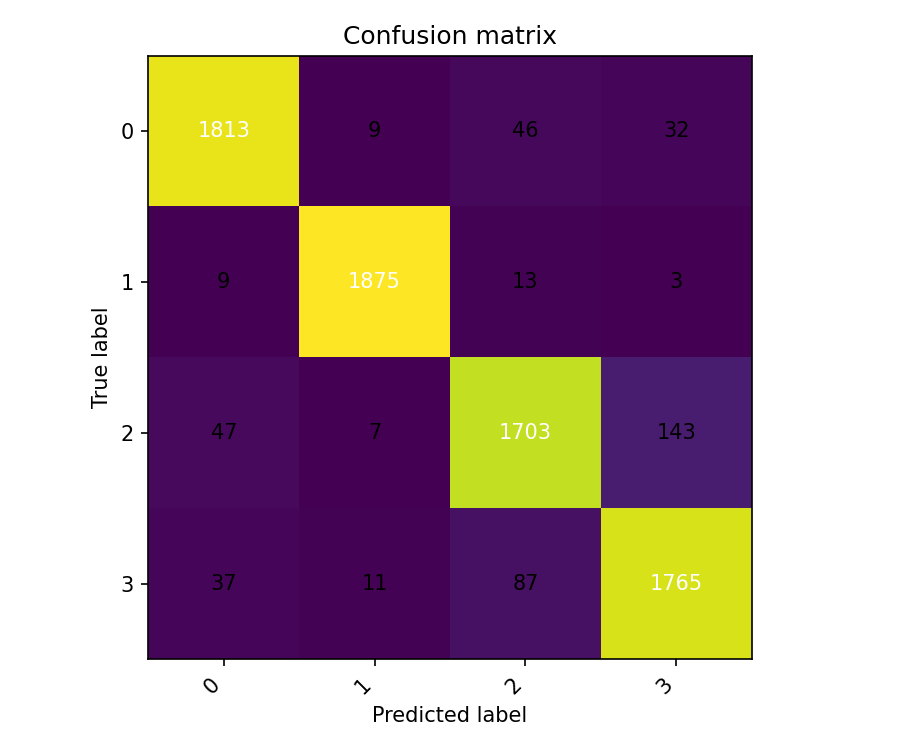


Example correct prediction:
Text (decoded): <no decoded text available>
True label: 2  Predicted: 2


In [19]:
# ===== Fixed evaluation cell: prints weighted metrics and shows a correct example =====
import torch
import numpy as np
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report
from IPython.display import Image, display
import matplotlib.pyplot as plt
import csv
import os

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = trainer.model
model.to(device)
model.eval()

def _extract_logits(outputs):
    if hasattr(outputs, "logits"):
        return outputs.logits
    if isinstance(outputs, dict):
        if "logits" in outputs:
            return outputs["logits"]
        for v in outputs.values():
            if isinstance(v, torch.Tensor) or isinstance(v, np.ndarray):
                return v
    if isinstance(outputs, (list, tuple)) and len(outputs) > 0:
        return outputs[0]
    raise RuntimeError(f"Could not extract logits from outputs of type {type(outputs)}")

def _to_numpy(x):
    if isinstance(x, torch.Tensor):
        return x.detach().cpu().numpy()
    return np.asarray(x)

def evaluate_and_show_example(trainer, dataset, id2label=None, task_type="auto", max_samples=200, cm_path="confusion_matrix.png", show_progress=True):
    # Infer task_type default (keeps previous behavior)
    if task_type == "auto":
        task_type = "sequence_classification"

    preds_all = []
    labs_all = []
    # We'll store small list of tuples to later locate a correct example: (input_ids, text_if_available, pred, label)
    saved_examples = []

    dl = trainer.get_eval_dataloader(dataset)
    iterator = dl if not show_progress else tqdm(dl, desc="Evaluating", leave=False)

    with torch.no_grad():
        for batch in iterator:
            # Move tensor values to device; keep non-tensors aside
            batch_device = {}
            for k, v in batch.items():
                try:
                    if isinstance(v, np.ndarray):
                        v = torch.from_numpy(v)
                    if isinstance(v, torch.Tensor):
                        batch_device[k] = v.to(device)
                except Exception:
                    pass

            model_inputs = {k: batch_device[k] for k in ("input_ids", "attention_mask", "token_type_ids") if k in batch_device}
            outputs = trainer.model(**model_inputs)
            logits = _extract_logits(outputs)
            logits_np = _to_numpy(logits)

            # labels
            if "labels" in batch_device:
                labels_np = _to_numpy(batch_device["labels"])
            elif "label" in batch_device:
                labels_np = _to_numpy(batch_device["label"])
            elif "labels" in batch:
                labels_np = _to_numpy(batch["labels"])
            else:
                # try to find a candidate tensor in original batch
                labels_np = None
                for k, v in batch.items():
                    if isinstance(v, (torch.Tensor, np.ndarray)):
                        arr = _to_numpy(v)
                        if arr.shape[0] == logits_np.shape[0] and (arr.ndim == 1 or (logits_np.ndim>1 and arr.shape[1] == logits_np.shape[1])):
                            labels_np = arr
                            break
                if labels_np is None:
                    labels_np = np.zeros((logits_np.shape[0],), dtype=int)

            # handle sequence vs token shapes: if 3D logits and labels 2D -> token_classification
            if logits_np.ndim == 3 and labels_np.ndim == 2 and labels_np.shape[1] == logits_np.shape[1]:
                this_task = "token_classification"
            else:
                this_task = task_type

            if this_task == "sequence_classification":
                if logits_np.ndim == 3:
                    # collapse token dimension: take first token logits (reasonable default)
                    logits_np = logits_np[:, 0, :]
                preds_batch = np.argmax(logits_np, axis=-1).reshape(-1)
                labels_batch = labels_np.reshape(-1)
                preds_all.extend(preds_batch.tolist())
                labs_all.extend(labels_batch.tolist())

                # Save examples for CSV and later correct-example search
                tokenizer = getattr(trainer, "tokenizer", None) or getattr(trainer.model, "tokenizer", None)
                # original batch input_ids for decoding
                if "input_ids" in batch:
                    batch_input_ids = batch["input_ids"]
                else:
                    batch_input_ids = None
                for i in range(preds_batch.shape[0]):
                    if len(saved_examples) < max_samples:
                        text = ""
                        if tokenizer is not None and batch_input_ids is not None:
                            ids = batch_input_ids[i]
                            try:
                                if isinstance(ids, torch.Tensor):
                                    ids = ids.cpu().numpy()
                                text = tokenizer.decode(ids, skip_special_tokens=True, clean_up_tokenization_spaces=True)
                            except Exception:
                                text = ""
                        saved_examples.append((text, int(preds_batch[i]), int(labels_batch[i])))

            else:  # token_classification
                # flatten token predictions where labels != -100
                batch_preds = np.argmax(logits_np, axis=-1)  # (batch, seq_len)
                if labels_np.ndim == 2 and labels_np.shape == batch_preds.shape:
                    mask = labels_np != -100
                    preds_flat = batch_preds[mask]
                    labs_flat = labels_np[mask]
                else:
                    # fallback: take first token
                    preds_flat = batch_preds[:, 0]
                    labs_flat = labels_np.reshape(-1) if labels_np.ndim >= 1 else np.zeros(preds_flat.shape[0], dtype=int)

                preds_all.extend(preds_flat.reshape(-1).tolist())
                labs_all.extend(labs_flat.reshape(-1).tolist())

                # save token-level textual sample (as CSV strings)
                tokenizer = getattr(trainer, "tokenizer", None) or getattr(trainer.model, "tokenizer", None)
                if "input_ids" in batch:
                    batch_input_ids = batch["input_ids"]
                else:
                    batch_input_ids = None
                for i in range(batch_preds.shape[0]):
                    if len(saved_examples) < max_samples:
                        text = ""
                        if tokenizer is not None and batch_input_ids is not None:
                            ids = batch_input_ids[i]
                            try:
                                if isinstance(ids, torch.Tensor):
                                    ids = ids.cpu().numpy()
                                text = tokenizer.decode(ids, skip_special_tokens=True, clean_up_tokenization_spaces=True)
                            except Exception:
                                text = ""
                        saved_examples.append((text, ",".join(map(str, batch_preds[i].tolist())), ",".join(map(str, labels_np[i].tolist() if labels_np.ndim==2 else [int(labels_np[i])]))))

    # finalize arrays
    preds_arr = np.asarray(preds_all, dtype=int)
    labs_arr = np.asarray(labs_all, dtype=int)

    if preds_arr.size == 0:
        raise RuntimeError("No predictions collected - check dataloader.")

    # compute metrics robustly:
    acc = accuracy_score(labs_arr, preds_arr)
    # get weighted scalars (safe to format)
    p_weighted, r_weighted, f_weighted, _ = precision_recall_fscore_support(labs_arr, preds_arr, average="weighted", zero_division=0)
    # per-class report as string
    report = classification_report(labs_arr, preds_arr, zero_division=0)
    cm = confusion_matrix(labs_arr, preds_arr)

    # Save confusion matrix image
    labels_for_plot = list(range(cm.shape[0])) if id2label is None else [id2label.get(i, str(i)) for i in range(cm.shape[0])]
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.imshow(cm, interpolation="nearest")
    ax.set_title("Confusion matrix")
    ax.set_xticks(np.arange(len(labels_for_plot))); ax.set_yticks(np.arange(len(labels_for_plot)))
    ax.set_xticklabels(labels_for_plot, rotation=45, ha="right"); ax.set_yticklabels(labels_for_plot)
    ax.set_ylabel("True label"); ax.set_xlabel("Predicted label")
    thresh = cm.max() / 2.0 if cm.max() > 0 else 1.0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, format(cm[i, j], "d"), ha="center", va="center",
                    color="white" if cm[i, j] > thresh else "black")
    plt.tight_layout()
    fig.savefig(cm_path, dpi=150)
    plt.close(fig)

    # save saved_examples to CSV (optional)
    csv_path = "predictions_sample.csv"
    with open(csv_path, "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["text", "pred", "label"])
        for text, pred, lab in saved_examples:
            writer.writerow([text, pred, lab])

    # print summary (fixed formatting)
    print("Evaluation summary:")
    print(f"  Task type: {task_type}")
    print(f"  Examples evaluated (predictions collected): {preds_arr.shape[0]}")
    print(f"  Accuracy: {acc:.4f}")
    print(f"  Weighted precision: {p_weighted:.4f}, recall: {r_weighted:.4f}, f1: {f_weighted:.4f}")
    print("\nClassification report (per-class):\n", report)
    print(f"Saved confusion matrix image to: {cm_path}")
    print(f"Saved sample predictions to: {csv_path}")

    # Show confusion matrix
    try:
        display(Image(cm_path))
    except Exception:
        pass

    # Find and print one correct example (first where pred == label)
    found = False
    for text, pred, lab in saved_examples:
        # saved_examples may contain string preds/labels for token tasks, handle both
        try:
            pred_int = int(pred) if isinstance(pred, (str, int)) and (isinstance(pred, int) or pred.isdigit()) else None
            lab_int = int(lab) if isinstance(lab, (str, int)) and (isinstance(lab, int) or lab.isdigit()) else None
        except Exception:
            pred_int = None; lab_int = None

        if pred_int is not None and lab_int is not None and pred_int == lab_int:
            print("\nExample correct prediction:")
            print("Text (decoded):", text if text else "<no decoded text available>")
            print("True label:", lab_int, " Predicted:", pred_int)
            found = True
            break

    if not found:
        print("\nNo single correct sample found in the saved examples (this is unusual if accuracy > 0). You can increase max_samples to capture a wider variety.")

    return {"accuracy": acc, "precision_weighted": p_weighted, "recall_weighted": r_weighted, "f1_weighted": f_weighted, "confusion_matrix": cm, "report": report, "cm_path": cm_path, "preds_csv": csv_path}

# ---- run evaluation (fixed) ----
metrics = evaluate_and_show_example(trainer, test, id2label=getattr(trainer, "id2label", None), task_type="auto", max_samples=500)


In [20]:
# ===== FINAL BACKUP CELL: Save all essential results to Drive =====
import os, shutil, json, torch, datetime

# === CONFIG ===
# put your Google Drive path here (change MyDrive/... if you want)
BASE_DRIVE_DIR = "/content/drive/MyDrive"
ASSIGNMENT_FOLDER = os.path.join(BASE_DRIVE_DIR, f"AGNEWS_RESULTS_{datetime.datetime.now().strftime('%Y%m%d_%H%M%S')}")

# what to save
FILES_TO_SAVE = [
    "confusion_matrix.png",
    "predictions_sample.csv",
    "model_state_dict_cpu.pth"
]
METRICS_VAR = "metrics"  # name of metrics variable in your notebook
TOKENIZER_DIR = "tokenizer"  # only copied if exists
# ==============

os.makedirs(ASSIGNMENT_FOLDER, exist_ok=True)
print(f"📂 Created new results folder: {ASSIGNMENT_FOLDER}")

# save metrics dict and report if available
if METRICS_VAR in globals():
    md = globals()[METRICS_VAR]
    def clean(obj):
        import numpy as np
        if isinstance(obj, dict): return {k: clean(v) for k, v in obj.items()}
        if isinstance(obj, (list, tuple)): return [clean(v) for v in obj]
        if isinstance(obj, torch.Tensor): return obj.cpu().tolist()
        if 'numpy' in str(type(obj)): return obj.tolist()
        return obj
    metrics_clean = clean(md)
    metrics_path = os.path.join(ASSIGNMENT_FOLDER, "metrics.json")
    with open(metrics_path, "w") as f:
        json.dump(metrics_clean, f, indent=2)
    print(f"✅ Saved metrics JSON → {metrics_path}")

    # classification report if exists
    if "report" in md:
        report_path = os.path.join(ASSIGNMENT_FOLDER, "classification_report.txt")
        with open(report_path, "w") as f:
            f.write(str(md["report"]))
        print(f"✅ Saved classification report → {report_path}")
else:
    print("⚠️ No variable 'metrics' found, skipping metrics export.")

print("\n🎉 All essential results saved successfully.")
print("📁 Drive folder:", ASSIGNMENT_FOLDER)


📂 Created new results folder: /content/drive/MyDrive/AGNEWS_RESULTS_20251005_102908
✅ Saved metrics JSON → /content/drive/MyDrive/AGNEWS_RESULTS_20251005_102908/metrics.json
✅ Saved classification report → /content/drive/MyDrive/AGNEWS_RESULTS_20251005_102908/classification_report.txt

🎉 All essential results saved successfully.
📁 Drive folder: /content/drive/MyDrive/AGNEWS_RESULTS_20251005_102908
